# Short-Term Rental Guest Feedback: Phase 2

INFO 4360 course project, Phase 2 (descriptive and exploratory work). Path B: find what guests complain about, where and when, so the COO knows what to fix first.

Data: Inside Airbnb, Broward County, FL, scraped 2026-06-29. The raw files are not in this repo (see `data/README.md`).

## 0. Setup

Load packages and the helper functions from `src/preprocessing.py`

In [1]:
import sys
sys.path.append("..")   # so the notebook can import from src/

import pandas as pd
import matplotlib.pyplot as plt

from src.preprocessing import strip_html, clean_text, looks_english, load_reviews

RAW = "../data/raw"   # reviews.csv.gz and listings.csv.gz go here

## 1. Data exploration

### 1.1 Size and coverage

In [2]:
# One row per review, joined with the details of its listing
df = load_reviews(RAW)

print("Reviews:", f"{len(df):,}")
print("Listings with reviews:", f"{df.listing_id.nunique():,}")
print("Dates:", df.date.min().date(), "to", df.date.max().date())
df.drop(columns="comments").head(3)   # text left out here on purpose

Reviews: 703,398
Listings with reviews: 14,249
Dates: 2011-08-23 to 2026-07-01


,listing_id,id,date,neighbourhood_cleansed,property_type,room_type,review_scores_rating,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location
0,4879228,24982610,2015-01-04,Pompano Beach,Room in aparthotel,Entire home/apt,4.0,4.50,4.50,5.00,4.00
1,4879228,1650842821850841956,2026-03-27,Pompano Beach,Room in aparthotel,Entire home/apt,4.0,4.50,4.50,5.00,4.00
2,4909030,25770307,2015-01-25,Fort Lauderdale,Private room in home,Private room,4.9,4.91,4.94,4.94,4.93


### 1.2 Missing values

In [3]:
# Share of missing values in each column (%)
(df.isna().mean() * 100).round(2).sort_values(ascending=False)

comments                       0.04
listing_id                     0.00
id                             0.00
date                           0.00
neighbourhood_cleansed         0.00
property_type                  0.00
room_type                      0.00
review_scores_rating           0.00
review_scores_cleanliness      0.00
review_scores_checkin          0.00
review_scores_communication    0.00
review_scores_location         0.00
dtype: float64

In [4]:
# Drop the reviews with no text, the only column we cannot work without
df = df[df.comments.notna()].copy()
print("Reviews with text:", f"{len(df):,}")

Reviews with text: 703,149


### 1.3 Reviews over time

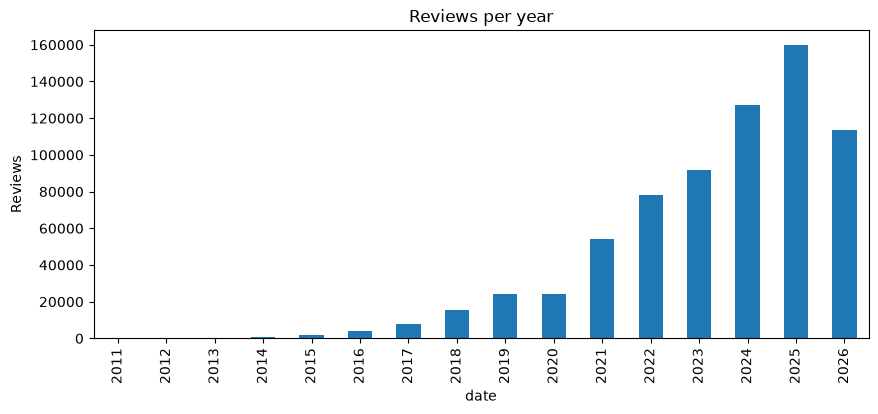

In [5]:
reviews_per_year = df.date.dt.year.value_counts().sort_index()

reviews_per_year.plot(kind="bar", figsize=(10, 4), title="Reviews per year")
plt.ylabel("Reviews")
plt.show()

### 1.4 Review sub-scores

There is no label for each review, but every listing has sub-scores from 1 to 5. One row per listing here, so big listings don't count more.

In [6]:
scores = ["review_scores_rating", "review_scores_cleanliness", "review_scores_communication",
          "review_scores_checkin", "review_scores_location"]
listing_scores = df.drop_duplicates("listing_id")[scores]
listing_scores.describe().round(2)

,review_scores_rating,review_scores_cleanliness,review_scores_communication,review_scores_checkin,review_scores_location
count,14247.00,14246.00,14246.00,14245.00,14245.00
mean,4.72,4.72,4.82,4.81,4.80
std,0.45,0.44,0.39,0.41,0.34
min,1.00,0.00,0.00,0.00,0.00
25%,4.67,4.65,4.80,4.79,4.75
50%,4.85,4.85,4.93,4.94,4.89
75%,4.98,4.98,5.00,5.00,5.00
max,5.00,5.00,5.00,5.00,5.00


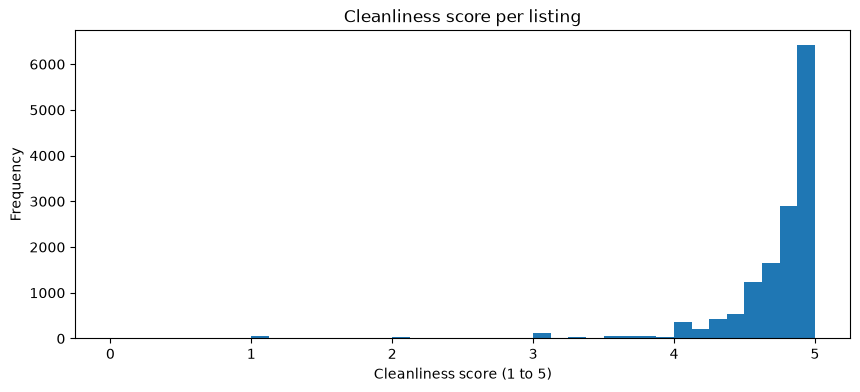

In [7]:
listing_scores.review_scores_cleanliness.plot(kind="hist", bins=40, figsize=(10, 4),
                                              title="Cleanliness score per listing")
plt.xlabel("Cleanliness score (1 to 5)")
plt.show()

### 1.5 Text length and language

count    703149.0
mean         36.8
std          40.1
min           1.0
25%          11.0
50%          24.0
75%          48.0
max        1298.0
Name: words, dtype: float64


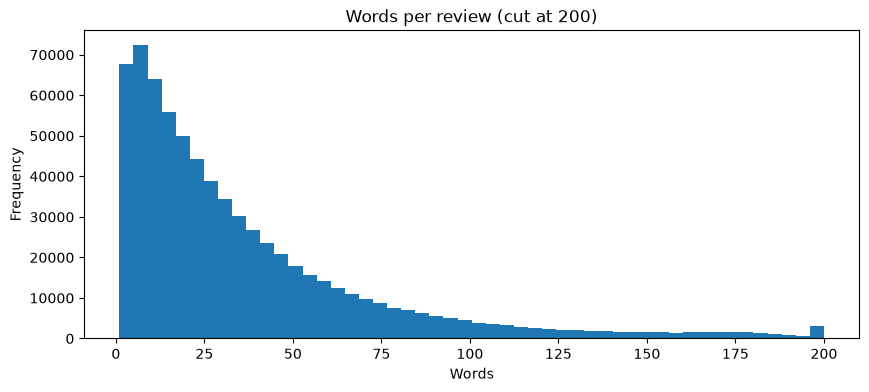

In [8]:
df["words"] = df.comments.str.split().str.len()
print(df.words.describe().round(1))

df.words.clip(upper=200).plot(kind="hist", bins=50, figsize=(10, 4),
                              title="Words per review (cut at 200)")
plt.xlabel("Words")
plt.show()

In [9]:
# Rough language check from src/preprocessing.py (share of common English words)
df["english"] = df.comments.map(looks_english)

print("English:", f"{df.english.mean():.0%}")
print("Very short (5 words or less):", f"{(df.words <= 5).mean():.0%}")
print("With HTML line breaks (<br/>):", f"{df.comments.str.contains('<br', regex=False).mean():.0%}")

English: 84%
Very short (5 words or less): 12%
With HTML line breaks (<br/>): 12%


### 1.6 What a review looks like

Inside Airbnb asks users not to republish its data, and this repo is public, so the examples below come from `data/sample_mock.csv`: made-up reviews in the same format, written to look like the real ones (praise, a broken AC, noise, a lockbox problem).

In [10]:
mock = pd.read_csv("../data/sample_mock.csv")
for text in mock.comments.head(5):
    print("-", text)

- Great location, two blocks from the beach. The place was spotless and check-in was easy.
- The air conditioning stopped working on the second night and it took a day to get someone to fix it.
- Very noisy at night. Loud music from the neighbors until 2am and nobody answered when we called.
- Nice view and comfortable beds. A bit dusty in the bathroom but nothing major.
- We could not find the lockbox and waited an hour outside with our luggage. Instructions were confusing.


### What the exploration tells us

- About 700,000 reviews of 14,000 listings, and most of them are recent: 2024 and 2025 are the biggest years. So recent years give plenty of data to compare areas and seasons.
- Missing values are not a problem. Only 249 reviews have no text.
- The sub-scores are packed near the top (median cleanliness 4.85 out of 5). That is the problem from Phase 1: the scores barely separate good homes from bad ones, so the useful signal has to come from the text.
- Reviews are short (median 24 words) and 12% have 5 words or less, like "Great place!". Short reviews say little about specific problems.
- 84% are in English. The text tools we use (VADER, English stop words) only work in English, so the rest of the analysis keeps English reviews only.